# M7.3 · 波动率曲面与交易

> 把不同行权价、期限的隐含波动率组织成曲面，呈现微笑/偏斜与期限结构；
> 波动率交易在 Delta 中性下押注隐含波动率与已实现波动率的差异。

## 一、机制

1. **微笑/偏斜**：IV 随 moneyness 变化，用二次/SVI/SABR 拟合；
2. **曲面**：行权价 × 期限的 IV 网格；
3. **波动率交易**：做空波动率者在已实现低于隐含时获利，可用方差互换表达。

## 二、曲面与交易

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np
from deriv_lab import vol_surface as vs
mny = np.array([0.9, 0.95, 1.0, 1.05, 1.1])
ivs = np.array([0.22, 0.205, 0.2, 0.205, 0.22])
coef = vs.fit_smile(mny, ivs)
print('ATM IV=%.4f 微笑曲率=%.4f' % (vs.smile_iv(coef, 1.0), coef[0]))
print('波动率交易损益(IV0.2 RV0.15)=%.2f' % vs.vol_trade_pnl(0.2, 0.15, 1000))
print('方差互换损益=%s' % vs.variance_swap_payoff(0.03, 0.04, 100000))

ATM IV=0.2000 微笑曲率=2.0000
波动率交易损益(IV0.2 RV0.15)=5000.00
方差互换损益=-1000.0000000000002


## 三、可视化：波动率微笑

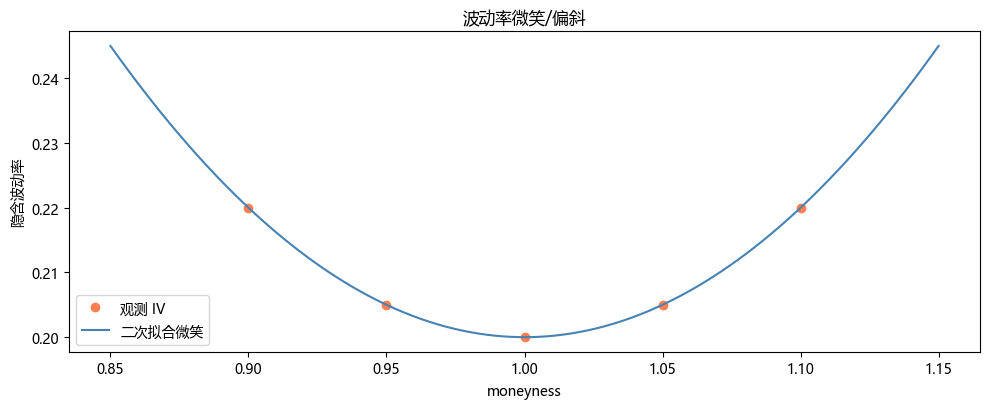

In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
grid = np.linspace(0.85, 1.15, 100)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(mny, ivs, 'o', color='coral', label='观测 IV')
ax.plot(grid, np.polyval(coef, grid), color='steelblue', label='二次拟合微笑')
ax.set_xlabel('moneyness'); ax.set_ylabel('隐含波动率'); ax.legend()
ax.set_title('波动率微笑/偏斜'); plt.tight_layout(); plt.show()

## 四、面试要点

- **为什么会有波动率微笑？** 崩盘风险、供需与杠杆效应，深度虚值看跌常被溢价。
- **隐含 vs 已实现波动率？** 隐含是期权定价的预期波动，已实现是标的实际波动，二者差异驱动波动率交易。
- **方差互换与普通期权区别？** 方差互换直接以已实现方差结算，无需 Delta 对冲即可获得纯波动率暴露。
- **曲面如何用于相对价值？** 比较同 moneyness/期限的 IV 高低，做多便宜点、做空贵点并保持中性。

## 五、练习

1. 实现 SVI 参数化曲面。
2. 计算波动率期限结构并解释。
3. 模拟 Delta 中性做空波动率的逐日损益。
4. 用真实期权链构建曲面。